# SK Hynix and the won: should a dollar investor hedge the currency?

**FM321 Assignment 1** | Candidate number: 60773 | Data: EODHD, 2 January 2013 to 6 November 2026

## Question

A US-dollar fund that buys SK Hynix on the Korea Exchange holds two risks: the share price in won, and the won itself. If the won tends to fall when SK Hynix falls, the fund is hit twice in a sell-off. This note describes both series with the Chapter 1 toolkit and asks:

> **Does the won add to or offset the risk of holding SK Hynix for a dollar investor, and should that investor hedge it?**

## Approach

1. Download daily prices for SK Hynix and the USD/KRW exchange rate from EODHD.
2. Plot prices and returns, and identify the major events in the sample.
3. Present sample statistics: moments, Jarque-Bera tests, QQ plots, tail probabilities, autocorrelations and Ljung-Box tests.
4. Show how volatility and correlation have evolved, using rolling windows, and how the won behaves in SK Hynix's worst weeks.
5. Measure how much the currency adds to a dollar investor's risk, and how much hedging would remove.
6. Make a recommendation based on the results.

Only Chapter 1 methods are used.

## 1. Setup

With `USE_CACHE = True` the notebook reads the submitted data file `fm321_a1_hynix_krw_data.csv`. With `False` it downloads the data from EODHD, which requires an `EOD_API_KEY` entry in a `.env` file. The sample end date is fixed so the results are reproducible. All statistics are coded from the formulas in the lecture slides using `numpy`, `pandas`, `scipy` and `matplotlib`.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from dotenv import load_dotenv

pd.set_option("display.width", 140)

# Parameters
START_DATE = "2013-01-01"
END_DATE = "2026-11-06"
DATA_FILE = "fm321_a1_hynix_krw_data.csv"
USE_CACHE = True
FIG_DIR = "figures_hynix_krw"
ANN = 250            # trading days per year, as in the lecture slides
ANN_W = 52           # weeks per year
ROLL_VOL = 63        # rolling volatility window, about one quarter
ROLL_CORR_W = 52     # rolling correlation window for weekly returns, one year
LB_LAGS = 21         # Ljung-Box lags, as in the lecture slides
ACF_LAGS = 50

TICKERS = {"HY": "000660.KO", "FX": "USDKRW.FOREX"}
LABEL = {"HY": "SK Hynix (KRW)", "FX": "USD/KRW", "HYUSD": "SK Hynix (USD)"}
COLOR = {"HY": "#B2182B", "FX": "#1B7837", "HYUSD": "#2166AC"}

# Events marked on the charts, numbered in this order
EVENTS = [
    ("2015-08-11", "Yuan devaluation"),
    ("2016-06-24", "Brexit vote"),
    ("2019-07-04", "Japan export curbs"),
    ("2020-03-16", "Covid crash"),
    ("2022-09-22", "Dollar surge"),
    ("2024-08-05", "Aug 2024 sell-off"),
    ("2024-12-03", "Martial law"),
    ("2025-04-03", "US tariffs"),
    ("2026-07-10", "SK Hynix US listing"),
]

# Sub-periods for the regime comparison
PERIODS = {"2013 to 2019": ("2013", "2019"), "2020 to 2022": ("2020", "2022"), "2023 to 2026": ("2023", "2026")}

# Figures are sized for an A4 page with 2.54 cm margins (6.3 inches wide)
FIG_W = 6.3
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 8,
    "axes.titlesize": 8.5, "axes.titlelocation": "left", "axes.labelsize": 8,
    "legend.fontsize": 7.5, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 0.9,
})

def show(df, dec=3):
    # Display a table with thousands separators, integers without decimals and very small or large numbers in scientific form
    def f(v):
        if isinstance(v, (bool, np.bool_)) or not isinstance(v, (int, float, np.integer, np.floating)):
            return v
        if isinstance(v, (int, np.integer)):
            return f"{v:,}"
        v = float(v)
        if np.isnan(v):
            return ""
        if v != 0 and (abs(v) < 1e-3 or abs(v) >= 1e7):
            return f"{v:.2e}"
        if v.is_integer() and abs(v) >= 10:
            return f"{v:,.0f}"
        return f"{v:,.{dec}f}"
    display(df.map(f) if hasattr(df, "map") else df.applymap(f))

def savefig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), bbox_inches="tight")

def year_axis(ax, step=2):
    ax.xaxis.set_major_locator(mdates.YearLocator(step))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

def mark_events(ax, numbers=True):
    dates = [pd.Timestamp(d) for d, _ in EVENTS]
    for i, d in enumerate(dates):
        ax.axvline(d, color="grey", ls=":", lw=0.7, zorder=0)
        if numbers:
            near_prev = i > 0 and (d - dates[i - 1]).days < 150
            near_next = i < len(dates) - 1 and (dates[i + 1] - d).days < 150
            ha = "center" if near_prev == near_next else ("left" if near_prev else "right")
            ax.text(d, 1.01, str(i + 1), transform=ax.get_xaxis_transform(),
                    fontsize=7, ha=ha, va="bottom", color="dimgrey")

## 2. Data

Daily prices come from EODHD: SK Hynix on the Korea Exchange (`000660.KO`, in KRW) and the USD/KRW exchange rate (`USDKRW.FOREX`, won per dollar). The SK Hynix close is adjusted for splits and dividends. Days with missing or non-positive prices are dropped, as are SK Hynix days with zero volume; foreign exchange carries no volume in the data. The FX series contains a small number of weekend quotes. They affect only the stand-alone FX statistics, because the joint analysis uses Korean trading days.

In [2]:
def fetch(ticker, start, end):
    from eodhd import APIClient
    load_dotenv()
    token = os.getenv("EOD_API_KEY")
    if token is None:
        raise RuntimeError("EOD_API_KEY not found in .env")
    data = APIClient(token).get_eod_historical_stock_market_data(ticker, from_date=start, to_date=end)
    df = pd.DataFrame(data)
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date").sort_index()
    df = df[~df.index.duplicated(keep="last")]
    adj = df["adjusted_close"] if "adjusted_close" in df else df["close"]
    return pd.DataFrame({"close": df["close"], "close_adj": adj, "volume": df["volume"]})

raw = {}
if USE_CACHE and os.path.exists(DATA_FILE):
    wide = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)
    for key in TICKERS:
        cols = [c for c in wide.columns if c.startswith(key + "_")]
        raw[key] = wide[cols].rename(columns=lambda c: c[len(key) + 1:]).dropna(how="all")
    print(f"Loaded {DATA_FILE}")
else:
    for key, ticker in TICKERS.items():
        raw[key] = fetch(ticker, START_DATE, END_DATE)
        time.sleep(1)
    wide = pd.concat(raw, axis=1, sort=True)
    wide.columns = [f"{k}_{c}" for k, c in wide.columns]
    wide.index.name = "date"
    wide.to_csv(DATA_FILE)
    print(f"Downloaded from EODHD and saved {DATA_FILE}")

def clean(df, volume_check):
    ok = df["close_adj"].notna() & (df["close_adj"] > 0)
    if volume_check:
        ok &= df["volume"] > 0
    return df[ok].copy(), int((~ok).sum())

HY, d_hy = clean(raw["HY"], True)
FX, d_fx = clean(raw["FX"], False)
show(pd.DataFrame({
    LABEL[k]: {"Ticker": TICKERS[k], "First date": df.index[0].date(), "Last date": df.index[-1].date(),
               "Trading days": len(df), "Rows dropped": d} for k, df, d in [("HY", HY, d_hy), ("FX", FX, d_fx)]}).T)

# Data checks for the exchange rate
s_own = np.log(FX["close_adj"]).diff().dropna()
print(f"USD/KRW days with an unchanged close: {(s_own.abs() < 1e-12).mean():.1%}")
print(f"USD/KRW quotes dated on a weekend: {(FX.index.dayofweek >= 5).sum()}")
print("Largest USD/KRW daily moves (%):")
show((s_own.reindex(s_own.abs().sort_values(ascending=False).index[:5]) * 100).to_frame("s_t %"), 2)

Loaded fm321_a1_hynix_krw_data.csv


,Ticker,First date,Last date,Trading days,Rows dropped
SK Hynix (KRW),000660.KO,2013-01-02,2026-11-06,"3,399",0
USD/KRW,USDKRW.FOREX,2013-01-01,2026-11-06,"3,659",0


USD/KRW days with an unchanged close: 0.4%
USD/KRW quotes dated on a weekend: 45
Largest USD/KRW daily moves (%):


,s_t %
date,
2020-03-24,-3.09
2025-04-09,-2.75
2022-11-11,-2.70
2016-06-24,2.61
2025-05-02,-2.55


### What the two series are

* **SK Hynix Inc.** (KRX: 000660) is a South Korean memory chipmaker within SK Group, producing DRAM and NAND flash. It is the leading supplier of high-bandwidth memory (HBM), the stacked DRAM used alongside Nvidia's AI accelerators, and one of the largest companies on the Korea Exchange.
* **USD/KRW** is the number of Korean won per US dollar, so a rise means the won has weakened. The won floats, with the Bank of Korea smoothing sharp moves. Korea's economy is export-driven, semiconductors are its largest export and foreign investors own a large share of its stock market, so the won and SK Hynix are exposed to the same global forces.

### The dollar investor's return

Following the lecture notation, $P_t$ is SK Hynix's adjusted close in won and $S_t$ the USD/KRW rate. The price in dollars is $P_t / S_t$, so with continuously compounded returns

$$y_t = \log P_t - \log P_{t-1}, \qquad s_t = \log S_t - \log S_{t-1}, \qquad y^{\$}_t = y_t - s_t.$$

The dollar investor earns the won return minus the change in the exchange rate. Its variance is

$$\sigma^2_{\$} = \sigma^2_y + \sigma^2_s - 2\,\text{Cov}(y, s),$$

so the currency adds risk unless SK Hynix tends to rise when the won weakens.

**Timing.** The Korea Exchange closes at 15:30 Seoul time, while EODHD's daily FX close is taken later in the global trading day. Same-date daily returns are therefore not perfectly synchronous. Weekly returns, taken on the last common trading day of each week, are almost unaffected, and are used for the dependence and hedging results.

In [3]:
# Joint data on the Korean trading calendar, with the exchange rate on the same date
J = pd.DataFrame({"P": HY["close_adj"]})
J["S"] = FX["close_adj"].reindex(J.index)
filled = int(J["S"].isna().sum())
J["S"] = J["S"].ffill(limit=2)
J = J.dropna()
J["P_usd"] = J["P"] / J["S"]
print(f"Korean trading days with no FX close on the same date, filled from the previous day: {filled}")

def log_returns(df):
    out = pd.DataFrame({"y": np.log(df["P"]).diff(), "s": np.log(df["S"]).diff()})
    out["y_usd"] = out["y"] - out["s"]
    return out.dropna()

rd = log_returns(J)                                   # daily, Korean calendar
W = J[["P", "S"]].resample("W-FRI").last().dropna()   # last common trading day of each week
rw = log_returns(W)                                   # weekly
print(f"Daily joint returns: {len(rd)}; weekly returns: {len(rw)}")

Korean trading days with no FX close on the same date, filled from the previous day: 0
Daily joint returns: 3398; weekly returns: 721


## 3. Prices

SK Hynix is shown in won and in dollars, both rebased to 1 on the first date and on a log scale. The gap between the two lines is the cumulative effect of the exchange rate. Numbered lines mark the events listed in the Setup cell.

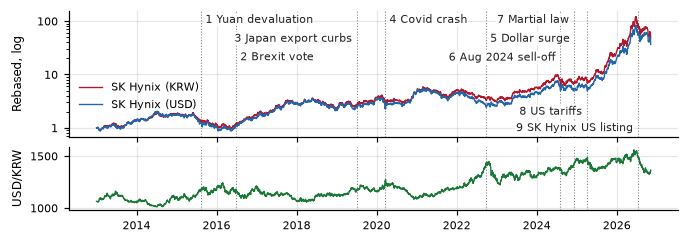

SK Hynix: 47.0x in won, 36.7x in dollars
Annual growth: 32.1% in won, 29.7% in dollars
USD/KRW: 1,064 at start, 1,364 at end, low 1,009 on 2014-07-03, high 1,559 on 2026-06-07


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(FIG_W, 2.25), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
rebased = J["P"] / J["P"].iloc[0]
axes[0].plot(J.index, rebased, color=COLOR["HY"], label=LABEL["HY"])
axes[0].plot(J.index, J["P_usd"] / J["P_usd"].iloc[0], color=COLOR["HYUSD"], label=LABEL["HYUSD"])
axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f"{v:g}"))
axes[0].yaxis.set_minor_formatter(plt.NullFormatter())
axes[0].set_ylabel("Rebased, log")
axes[0].legend(loc="upper left", bbox_to_anchor=(0.0, 0.52), frameon=False)
axes[1].plot(FX.index, FX["close_adj"], color=COLOR["FX"])
axes[1].set_ylabel("USD/KRW")
for ax in axes:
    mark_events(ax, numbers=False)

# Name each event beside its line. For each event in EVENTS: height in the panel, and side of the line for the text
LABEL_POS = [(0.93, "right"), (0.63, "right"), (0.78, "left"), (0.93, "right"), (0.78, "right"),
             (0.63, "left"), (0.93, "left"), (0.20, "left"), (0.07, "left")]
for i, ((d, lab), (yy, side)) in enumerate(zip(EVENTS, LABEL_POS)):
    axes[0].annotate(f"{i + 1} {lab}", xy=(mdates.date2num(pd.Timestamp(d)), yy), xycoords=axes[0].get_xaxis_transform(),
                     xytext=(3 if side == "right" else -3, 0), textcoords="offset points",
                     ha="left" if side == "right" else "right", va="center", fontsize=7, color="#222222",
                     bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=0.6))
year_axis(axes[1])
fig.tight_layout(h_pad=0.4)
fig.align_ylabels(axes)
savefig(fig, "fig1_prices")
plt.show()

years = (J.index[-1] - J.index[0]).days / 365.25
growth_krw = (J["P"].iloc[-1] / J["P"].iloc[0]) ** (1 / years) - 1
growth_usd = (J["P_usd"].iloc[-1] / J["P_usd"].iloc[0]) ** (1 / years) - 1
print(f"SK Hynix: {J['P'].iloc[-1] / J['P'].iloc[0]:.1f}x in won, {J['P_usd'].iloc[-1] / J['P_usd'].iloc[0]:.1f}x in dollars")
print(f"Annual growth: {growth_krw:.1%} in won, {growth_usd:.1%} in dollars")
print(f"USD/KRW: {FX['close_adj'].iloc[0]:,.0f} at start, {FX['close_adj'].iloc[-1]:,.0f} at end, "
      f"low {FX['close_adj'].min():,.0f} on {FX['close_adj'].idxmin().date()}, "
      f"high {FX['close_adj'].max():,.0f} on {FX['close_adj'].idxmax().date()}")

**Interpretation.**

* **Currency drag.** SK Hynix rose 47.0 times in won but 36.7 times in dollars, 32.1% against 29.7% a year, because the won weakened from 1,064 to 1,364 per dollar. The currency cost a dollar investor about 2.4 percentage points a year.
* **Non-stationarity.** Both prices trend and break at identifiable events, which is why the analysis works with returns from here on.

*SK Hynix: from a memory cycle to an AI trade*

* **Yuan devaluation (1).** Memory is a commodity business with a pronounced price cycle. SK Hynix fell through 2015 as DRAM prices dropped on weak PC and smartphone demand, and China's devaluation added to the pressure, since China is Korea's largest export market.
* **2017 to 2018 upcycle.** Data-centre demand lifted DRAM prices and earnings to a peak in 2018; as new supply arrived, prices turned and the stock fell back.
* **Japan export curbs (3).** In July 2019 Japan restricted exports to Korea of three chipmaking materials, a supply-chain risk for Korean chipmakers on top of the US-China trade dispute.
* **Covid crash (4).** SK Hynix fell with global equities in March 2020, then recovered quickly as remote work and cloud spending supported memory demand.
* **The AI rally.** Leadership in HBM turned SK Hynix into a direct beneficiary of AI investment. The August 2024 sell-off (6), triggered by the unwinding of yen carry trades, and the US tariff shock (8) were only interruptions to a rise that accelerated through 2025.
* **The 2026 peak.** SK Hynix peaked in June 2026, just before its US listing (9), and then fell sharply.

*The won: a risk-off currency*

* **Brexit vote (2).** The won fell 2.6% in a day although Korea had little direct exposure: in global sell-offs investors move into the dollar and out of currencies tied to trade and growth.
* **Covid crash (4).** The won weakened as dollar funding tightened worldwide, then rebounded once the Federal Reserve opened a swap line with the Bank of Korea.
* **Dollar surge (5).** Rapid US rate rises in 2022 strengthened the dollar against most currencies, and USD/KRW rose above 1,400.
* **Korean martial law (7).** The December 2024 political shock led foreign investors to sell Korean assets, and the won stayed weak into 2025.
* **Late 2026.** The won strengthened from its June peak of 1,559 to 1,364.

*Why this matters.* When global risk appetite falls, foreign investors sell Korean shares and convert the proceeds into dollars, which pushes down both SK Hynix and the won. A dollar investor can therefore be hit twice in the same sell-off. Sections 7 and 8 test whether this happens systematically.

## 4. Returns

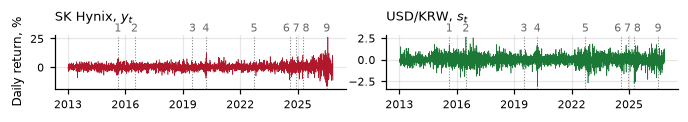

SK Hynix largest daily moves, with the same-date exchange rate move


,y_t %,s_t %,y_t in USD %
date,,,
2026-07-31,26.20,1.33,24.87
2026-07-13,-16.68,-0.08,-16.61
2026-07-28,-15.84,-0.82,-15.02
2026-07-02,-15.75,-0.69,-15.05
2026-06-09,14.76,-0.24,15.01
2026-06-23,-13.32,-0.36,-12.96
2020-03-24,12.58,-3.09,15.67
2026-06-25,12.28,0.15,12.12


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 1.15))
axes[0].plot(rd.index, rd["y"] * 100, color=COLOR["HY"], lw=0.4)
axes[0].set_title("SK Hynix, $y_t$", pad=9)
axes[1].plot(s_own.index, s_own * 100, color=COLOR["FX"], lw=0.4)
axes[1].set_title("USD/KRW, $s_t$", pad=9)
for ax in axes:
    mark_events(ax)
    year_axis(ax, 3)
axes[0].set_ylabel("Daily return, %")
fig.tight_layout()
savefig(fig, "fig2_returns")
plt.show()

top = rd.reindex(rd["y"].abs().sort_values(ascending=False).index[:8])[["y", "s", "y_usd"]] * 100
top.columns = ["y_t %", "s_t %", "y_t in USD %"]
print("SK Hynix largest daily moves, with the same-date exchange rate move")
show(top, 2)

**Interpretation.**

* **Volatility clusters.** Both series fluctuate around a mean of close to zero, with bursts of large moves, as the lecture's stylised facts predict.
* **SK Hynix's largest moves are stock-specific.** Seven of its eight largest daily moves came in June and July 2026, around the peak and the US listing (9), and on those days the exchange rate moved by less than 1.4%.
* **The won's largest moves are macro events.** Four of its five largest daily moves are gains, three of them when global dollar stress eased: 24 March 2020 after the Federal Reserve's swap line (4), 11 November 2022 after softer US inflation data ended the dollar surge (5) and 9 April 2025 when the US paused its tariffs (8). The fourth came on 2 May 2025, and the fifth move is the Brexit vote (2), a 2.6% fall.
* **The two effects can compound.** On 24 March 2020 SK Hynix rose 12.6% in won while the won gained 3.1%, so a dollar investor made 15.7%.

## 5. Sample statistics

The estimators follow the lecture slides: variance divides by $T-1$, while skewness and kurtosis are sample moments dividing by $T$. Volatility is annualised with $\sqrt{250}$. Normality is tested with

$$JB = \frac{T}{6}\,\text{Skewness}^2 + \frac{T}{24}(\text{Kurtosis}-3)^2 \sim \chi^2(2),$$

and autocorrelation with the Ljung-Box test on $N = 21$ lags,

$$LB = T(T+2)\sum_{i=1}^{N}\frac{\hat\rho_i^2}{T-i} \sim \chi^2(N).$$

The exchange rate is summarised on its own trading calendar, and SK Hynix in won and in dollars on the Korean calendar.

In [6]:
def acf(x, nlags):
    x = np.asarray(x, dtype=float) - np.mean(x)
    denom = np.sum(x ** 2)
    return np.array([np.sum(x[i:] * x[:-i]) / denom for i in range(1, nlags + 1)])

def ljung_box(x, nlags=LB_LAGS):
    T = len(x)
    rho = acf(x, nlags)
    lb = T * (T + 2) * np.sum(rho ** 2 / (T - np.arange(1, nlags + 1)))
    return lb, stats.chi2.sf(lb, nlags)

def describe(x):
    x = pd.Series(x).dropna().values
    T = len(x)
    mu, sd = x.mean(), x.std(ddof=1)
    z = (x - mu) / sd
    skew, kurt = np.mean(z ** 3), np.mean(z ** 4)
    jb = T / 6 * skew ** 2 + T / 24 * (kurt - 3) ** 2
    lb, lb_p = ljung_box(x)
    lb2, lb2_p = ljung_box(x ** 2)
    return {"T": T, "Mean (%)": mu * 100, "Std. dev. (%)": sd * 100,
            "Ann. volatility (%)": sd * np.sqrt(ANN) * 100,
            "Min (%)": x.min() * 100, "Max (%)": x.max() * 100,
            "Skewness": skew, "Kurtosis": kurt,
            "Jarque-Bera": jb, "JB p-value": stats.chi2.sf(jb, 2),
            "LB(21) y": lb, "LB(21) y p-value": lb_p,
            "LB(21) y^2": lb2, "LB(21) y^2 p-value": lb2_p}

series = {LABEL["HY"]: rd["y"], LABEL["FX"]: s_own, LABEL["HYUSD"]: rd["y_usd"]}
table1 = pd.DataFrame({k: describe(v) for k, v in series.items()})
show(table1)

,SK Hynix (KRW),USD/KRW,SK Hynix (USD)
T,"3,398","3,658","3,398"
Mean (%),0.113,0.007,0.106
Std. dev. (%),2.775,0.531,2.874
Ann. volatility (%),43.872,8.395,45.437
Min (%),-16.685,-3.095,-16.605
Max (%),26.202,2.611,24.875
Skewness,0.111,-0.190,0.088
Kurtosis,8.558,4.854,7.572
Jarque-Bera,"4,380.149",546.278,"2,964.424"
JB p-value,0.000,2.38e-119,0.000


**Interpretation.**

* **The currency adds risk.** Annualised volatility is 43.9% for SK Hynix in won, 8.4% for USD/KRW and 45.4% for SK Hynix in dollars.
* **Means are negligible** next to standard deviations, so the analysis focuses on risk rather than return.
* **Fat tails.** Kurtosis of 8.6, 4.9 and 7.6, with Jarque-Bera p-values of essentially zero, rejects normality for all three series; the exchange rate's tails are much thinner than the stock's.
* **Volatility clustering.** Ljung-Box statistics for squared returns (2,430, 454 and 1,989) are many times larger than for returns (80, 36 and 64): volatility is predictable while returns are close to unpredictable, consistent with weak-form efficiency. The return tests also reject at 5%, but with more than 3,000 observations even economically negligible autocorrelations are significant.

### 5.1 How unlikely are the largest moves under normality?

For each series, the probability that a normal distribution with the sample mean and standard deviation produces a daily move at least as large as the largest observed one, in either direction, and the expected waiting time between such moves. The Student-t degrees of freedom $\nu$ implied by the sample kurtosis follow from $\text{Kurtosis} = 3 + 6/(\nu - 4)$.

In [7]:
tails = {}
for name, x in series.items():
    mu, sd = x.mean(), x.std(ddof=1)
    z = (x - mu).abs().max() / sd
    p = 2 * stats.norm.sf(z)
    kurt = table1.loc["Kurtosis", name]
    tails[name] = {"Largest move (%)": x.loc[(x - mu).abs().idxmax()] * 100,
                   "Date": (x - mu).abs().idxmax().date(),
                   "Standard deviations": z,
                   "Normal probability per day": p,
                   "Expected wait (years)": 1 / (p * ANN),
                   "Implied Student-t nu": 4 + 6 / (kurt - 3) if kurt > 3 else np.nan}
tail_table = pd.DataFrame(tails).T
show(tail_table)

,Largest move (%),Date,Standard deviations,Normal probability per day,Expected wait (years),Implied Student-t nu
SK Hynix (KRW),26.202,2026-07-31,9.402,5.35e-21,7.48e+17,5.080
USD/KRW,-3.095,2020-03-24,5.841,5.18e-09,"772,623.479",7.235
SK Hynix (USD),24.875,2026-07-31,8.619,6.74e-18,5.93e+14,5.312


**Interpretation.**

* SK Hynix's 26.2% gain on 31 July 2026 was a 9.4 standard deviation move, which a normal distribution would produce about once in $7 \times 10^{17}$ years.
* The won's 3.1% rise on 24 March 2020 was a 5.8 standard deviation move, about once in 770,000 years.
* The implied Student-t degrees of freedom are 5.1 for SK Hynix, close to the lecture's range of 3 to 5 for stocks, and 7.2 for the exchange rate: fat tails in both, but less extreme for the currency. A risk model built on the normal would badly understate both.

### 5.2 Fat tails: QQ plots

Standardised returns against the standard normal (top) and a Student-t scaled to unit variance (bottom), with degrees of freedom set to the implied value from Section 5.1, rounded and at least 3.

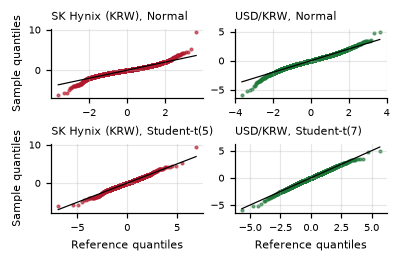

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(3.5, 2.25))
for j, (key, x) in enumerate([("HY", rd["y"]), ("FX", s_own)]):
    x = x.values
    z = np.sort((x - x.mean()) / x.std(ddof=1))
    p = (np.arange(1, len(z) + 1) - 0.5) / len(z)
    nu = int(max(3, round(tail_table.loc[LABEL[key], "Implied Student-t nu"])))
    refs = [(stats.norm.ppf(p), "Normal"), (stats.t.ppf(p, nu) * np.sqrt((nu - 2) / nu), f"Student-t({nu})")]
    for i, (q, name) in enumerate(refs):
        ax = axes[i, j]
        ax.scatter(q, z, s=3, color=COLOR[key], alpha=0.6)
        ax.plot([q.min(), q.max()], [q.min(), q.max()], color="black", lw=0.8)
        ax.set_title(f"{LABEL[key]}, {name}", fontsize=7.5)
        ax.tick_params(labelsize=6.5)
for ax in axes[:, 0]:
    ax.set_ylabel("Sample quantiles", fontsize=7)
for ax in axes[1, :]:
    ax.set_xlabel("Reference quantiles", fontsize=7)
fig.tight_layout(pad=0.3, h_pad=0.6, w_pad=0.6)
savefig(fig, "fig3_qq")
plt.show()

**Interpretation.** Against the normal, both series show the S shape from the lecture, with the extreme quantiles bending away from the line in both tails. Against the Student-t with the implied degrees of freedom, the points lie close to the line, with only a few extreme observations off it.

### 5.3 Volatility clusters

Autocorrelations of returns and squared returns, with approximate 95% bounds of $\pm 1.96/\sqrt{T}$.

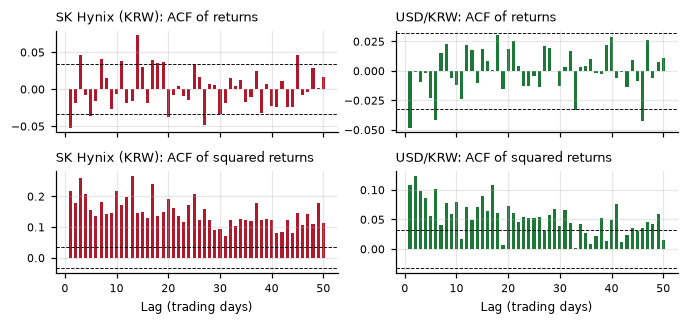

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(FIG_W, 3.0), sharex=True)
lags = np.arange(1, ACF_LAGS + 1)
for j, (key, x) in enumerate([("HY", rd["y"]), ("FX", s_own)]):
    x = x.values
    band = 1.96 / np.sqrt(len(x))
    for i, (sr, name) in enumerate([(x, "returns"), (x ** 2, "squared returns")]):
        ax = axes[i, j]
        ax.bar(lags, acf(sr, ACF_LAGS), width=0.6, color=COLOR[key])
        for b in (band, -band):
            ax.axhline(b, color="black", ls="--", lw=0.6)
        ax.set_title(f"{LABEL[key]}: ACF of {name}")
for ax in axes[1]:
    ax.set_xlabel("Lag (trading days)")
fig.tight_layout()
savefig(fig, "fig4_acf")
plt.show()

**Interpretation.** Return autocorrelations are small for both series, below 0.08 in absolute value, with a few just outside the bounds. Squared-return autocorrelations are positive and well above the bounds: for SK Hynix between about 0.1 and 0.27 at all 50 lags, for USD/KRW starting near 0.12 and decaying slowly. Both markets show the volatility clustering described in the lecture.

## 6. Volatility over time

Rolling historical volatility over 63 trading days, annualised with $\sqrt{250}$. The top panel compares SK Hynix in won and in dollars, the bottom panel shows the exchange rate.

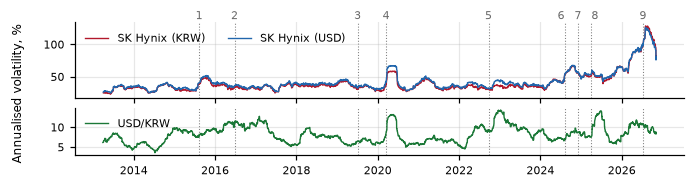

SK Hynix (KRW)  rolling volatility: median 35.2%, min 22.6%, max 128.5% on 2026-08-03
SK Hynix (USD)  rolling volatility: median 37.3%, min 24.3%, max 126.2% on 2026-08-04
USD/KRW         rolling volatility: median 7.9%, min 3.5%, max 14.3% on 2023-01-09
Dollar minus won volatility: mean +1.9 pp, share of days the dollar volatility is higher 94%
Correlation of SK Hynix and USD/KRW rolling volatilities: 0.25


In [10]:
vol = {"HY": rd["y"].rolling(ROLL_VOL).std() * np.sqrt(ANN) * 100,
       "HYUSD": rd["y_usd"].rolling(ROLL_VOL).std() * np.sqrt(ANN) * 100,
       "FX": s_own.rolling(ROLL_VOL).std() * np.sqrt(ANN) * 100}

fig, axes = plt.subplots(2, 1, figsize=(FIG_W, 1.75), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
for key in ["HY", "HYUSD"]:
    axes[0].plot(vol[key].index, vol[key], color=COLOR[key], label=LABEL[key])
axes[0].legend(loc="upper left", ncol=2, frameon=False)
axes[1].plot(vol["FX"].index, vol["FX"], color=COLOR["FX"], label=LABEL["FX"])
axes[1].legend(loc="upper left", frameon=False)
fig.supylabel("Annualised volatility, %", fontsize=8, x=0.01)
mark_events(axes[0])
mark_events(axes[1], numbers=False)
year_axis(axes[1])
fig.tight_layout(h_pad=0.4)
fig.align_ylabels(axes)
savefig(fig, "fig5_volatility")
plt.show()

for key in vol:
    v = vol[key].dropna()
    print(f"{LABEL[key]:15s} rolling volatility: median {v.median():.1f}%, min {v.min():.1f}%, "
          f"max {v.max():.1f}% on {v.idxmax().date()}")
gap = (vol["HYUSD"] - vol["HY"]).dropna()
print(f"Dollar minus won volatility: mean {gap.mean():+.1f} pp, share of days the dollar volatility is higher {(gap > 0).mean():.0%}")
vj = pd.concat([vol["HY"], vol["FX"].reindex(vol["HY"].index)], axis=1).dropna()
print(f"Correlation of SK Hynix and USD/KRW rolling volatilities: {vj.corr().iloc[0, 1]:.2f}")

**Interpretation.**

* **SK Hynix's volatility clusters around events.** It rose to about 50% after the yuan devaluation (1), about 65% in the Covid crash (4) and the August 2024 sell-off (6), and a record 128% in mid-2026 around the peak and US listing (9).
* **The won's volatility clusters too,** ranging from 3.5% to 14.3%. It peaked in 2015 and 2016 (1, 2), at Covid (4), in the 2022 dollar surge (5) and around the 2025 tariffs (8): global macro shocks rather than Korean ones.
* **The dollar investor bears more risk.** SK Hynix is more volatile in dollars than in won on 94% of days, by 1.9 percentage points on average, and the gap is widest when the won itself is volatile, as at Covid.
* **The two volatilities are only loosely related** (correlation 0.25): they rise together in global shocks such as Covid, but the 2026 spike was specific to SK Hynix.

## 7. Correlation over time

### 7.1 Full sample

The correlation between SK Hynix's return $y_t$ and the exchange rate return $s_t$ is reported on three bases: same-date daily returns, daily returns with the next day's exchange rate move (to allow for the later FX close), and weekly returns. A negative correlation means the won tends to weaken when SK Hynix falls. The slope $\hat\beta = \widehat{\text{Cov}}(y, s)/\hat\sigma^2_s$ from the lecture's $y = \beta x + \epsilon$ is also shown.

In [11]:
def pair(x, y):
    d = pd.concat([x, y], axis=1).dropna()
    rho = d.iloc[:, 0].corr(d.iloc[:, 1])
    beta = d.cov().iloc[0, 1] / d.iloc[:, 0].var()
    return {"Correlation": rho, "95% bound": 1.96 / np.sqrt(len(d)), "beta of y on s": beta, "T": len(d)}

table2 = pd.DataFrame({
    "Daily, same date":             pair(rd["s"], rd["y"]),
    "Daily, next-day FX move":      pair(rd["s"].shift(-1), rd["y"]),
    "Weekly":                       pair(rw["s"], rw["y"]),
}).T
show(table2)

,Correlation,95% bound,beta of y on s,T
"Daily, same date",-0.085,0.034,-0.432,"3,398"
"Daily, next-day FX move",-0.029,0.034,-0.144,"3,397"
Weekly,-0.220,0.073,-1.078,721


**Interpretation.**

* **The won tends to weaken when SK Hynix falls.** The weekly correlation is -0.22, far outside the 95% bound of 0.073, and the slope implies that a 1% weakening of the won in a week coincides with a 1.08% fall in SK Hynix.
* **Daily data understate the link.** The daily correlation is only -0.09, because the two markets close at different times of day and daily moves are noisier. Allowing for the later FX close does not strengthen it, so weekly returns are the better basis.

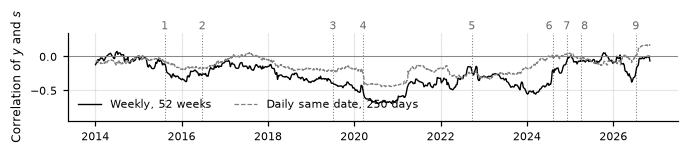

,2013 to 2019,2020 to 2022,2023 to 2026
Weekly correlation,-0.232,-0.423,-0.125
Daily same-date correlation,-0.108,-0.305,0.025
Weekly T,363,157,201


Rolling weekly correlation: min -0.70 on 2020-07-24, max 0.07 on 2014-07-04


In [12]:
roll_w = rw["y"].rolling(ROLL_CORR_W).corr(rw["s"])
roll_d = rd["y"].rolling(250).corr(rd["s"])

fig, ax = plt.subplots(figsize=(FIG_W, 1.35))
ax.plot(roll_w.index, roll_w, color="black", label="Weekly, 52 weeks")
ax.plot(roll_d.index, roll_d, color="grey", ls="--", lw=0.8, label="Daily same date, 250 days")
ax.axhline(0, color="grey", lw=0.6)
ax.set_ylabel("Correlation of $y$ and $s$")
ax.set_ylim(-0.95, 0.35)
ax.legend(loc="lower left", ncol=2, frameon=False)
mark_events(ax)
year_axis(ax)
fig.tight_layout()
savefig(fig, "fig6_correlation")
plt.show()

table3 = pd.DataFrame({
    name: {"Weekly correlation": rw.loc[a:b, "y"].corr(rw.loc[a:b, "s"]),
           "Daily same-date correlation": rd.loc[a:b, "y"].corr(rd.loc[a:b, "s"]),
           "Weekly T": len(rw.loc[a:b])}
    for name, (a, b) in PERIODS.items()})
show(table3)
print(f"Rolling weekly correlation: min {roll_w.min():.2f} on {roll_w.idxmin().date()}, "
      f"max {roll_w.max():.2f} on {roll_w.idxmax().date()}")

**Interpretation.**

* **The link is persistent.** The rolling weekly correlation has been negative almost throughout: -0.23 in 2013 to 2019, -0.42 in 2020 to 2022 and -0.13 since 2023.
* **It strengthens in global, macro-driven markets.** It turned negative after the yuan devaluation (1) and the Brexit vote (2), deepened through the 2019 trade tensions (3), and reached -0.70 in the year around the Covid crash (4), when a single factor, global risk appetite, drove both markets. It was around -0.5 again in 2023 and 2024, during the long period of high US interest rates.
* **It weakens when stock-specific news dominates.** It moved close to zero during the AI rally of 2025 and again in late 2026, when the won strengthened while SK Hynix fell from its peak.
* **Implication.** The currency risk is largest exactly when global markets are under stress, which is when a fund can least afford it.

In [13]:
lo, hi = rw["y"].quantile([0.10, 0.90])
groups = {"Worst 10% of weeks": rw[rw["y"] <= lo], "Middle 80%": rw[(rw["y"] > lo) & (rw["y"] < hi)],
          "Best 10% of weeks": rw[rw["y"] >= hi]}
table4 = pd.DataFrame({name: {"Weeks": len(g), "Mean SK Hynix return (%)": g["y"].mean() * 100,
                              "Mean USD/KRW move (%)": g["s"].mean() * 100,
                              "Share of weeks the won weakened (%)": (g["s"] > 0).mean() * 100,
                              "Mean dollar return (%)": g["y_usd"].mean() * 100}
                       for name, g in groups.items()}).T
show(table4, 2)

,Weeks,Mean SK Hynix return (%),Mean USD/KRW move (%),Share of weeks the won weakened (%),Mean dollar return (%)
Worst 10% of weeks,73,-9.30,0.45,65.75,-9.75
Middle 80%,575,0.50,0.04,51.13,0.46
Best 10% of weeks,73,10.63,-0.43,39.73,11.06


**Interpretation.**

* **Downside.** In SK Hynix's worst 10% of weeks, averaging -9.3%, the won weakened in two weeks out of three, by 0.45% on average, so a dollar investor lost 9.75%.
* **Upside.** In its best 10% of weeks the won tended to strengthen, adding to the dollar gain.
* **Normal weeks.** In the middle 80% of weeks the won showed no direction, weakening in 51% of them.
* **Non-linear dependence.** The link is concentrated in the extreme weeks, the pattern described in the lecture: a single correlation coefficient averages it away, and a normal-based model would miss it.

## 8. How much risk does the currency add, and how much would hedging remove?

A dollar investor who hedges a fraction $h$ of the won exposure earns approximately

$$y^{\$}_t(h) = y_t - (1 - h)\,s_t,$$

so $h = 0$ is unhedged and $h = 1$ fully hedged. Minimising the variance of $y^{\$}_t(h)$ gives the variance-minimising hedge ratio

$$h^{*} = 1 - \frac{\widehat{\text{Cov}}(y, s)}{\hat\sigma^2_s},$$

which exceeds 1 when SK Hynix and the won tend to fall together. The calculation uses weekly returns and ignores the forward points of a currency hedge, which reflect the interest rate differential and are outside the scope of Chapter 1.

,Full sample,2013 to 2019,2020 to 2022,2023 to 2026
Won volatility (%),40.61,31.52,35.26,55.78
FX volatility (%),8.30,7.51,8.91,9.15
Unhedged dollar volatility (%),43.20,34.05,39.85,57.65
Fully hedged volatility (%),40.61,31.52,35.26,55.78
h*,2.08,1.97,2.68,1.77
Volatility at h* (%),39.61,30.67,31.94,55.34
Volatility added by the won (pp),2.59,2.53,4.60,1.87


Dollar variance = won variance 0.1649 + FX variance 0.0069 - 2 x covariance -0.0074 = 0.1866 (check 0.1866)


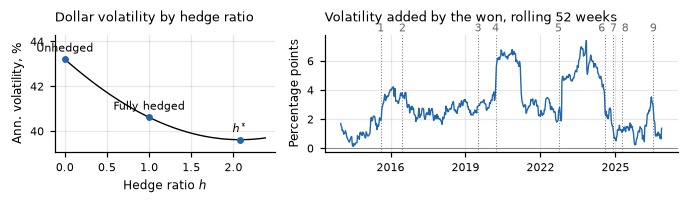

Rolling volatility added by the won: mean +3.0 pp, min +0.1 pp, max +7.4 pp on 2023-11-03


In [14]:
def hedge_stats(d):
    h_star = 1 - d["y"].cov(d["s"]) / d["s"].var()
    ann = np.sqrt(ANN_W) * 100
    out = {"Won volatility (%)": d["y"].std() * ann,
           "FX volatility (%)": d["s"].std() * ann,
           "Unhedged dollar volatility (%)": d["y_usd"].std() * ann,
           "Fully hedged volatility (%)": d["y"].std() * ann,
           "h*": h_star,
           "Volatility at h* (%)": (d["y"] - (1 - h_star) * d["s"]).std() * ann}
    out["Volatility added by the won (pp)"] = out["Unhedged dollar volatility (%)"] - out["Won volatility (%)"]
    return out

table5 = pd.DataFrame({"Full sample": hedge_stats(rw), **{n: hedge_stats(rw.loc[a:b]) for n, (a, b) in PERIODS.items()}})
show(table5, 2)

# Variance decomposition, weekly, annualised
vy, vs, cv = rw["y"].var() * ANN_W, rw["s"].var() * ANN_W, rw["y"].cov(rw["s"]) * ANN_W
print(f"Dollar variance = won variance {vy:.4f} + FX variance {vs:.4f} - 2 x covariance {cv:.4f} "
      f"= {vy + vs - 2 * cv:.4f} (check {rw['y_usd'].var() * ANN_W:.4f})")

h_star = table5.loc["h*", "Full sample"]
h_grid = np.linspace(0, max(1.5, h_star + 0.3), 61)
vols = [(rw["y"] - (1 - h) * rw["s"]).std() * np.sqrt(ANN_W) * 100 for h in h_grid]

roll_gap = (rw["y_usd"].rolling(ROLL_CORR_W).std() - rw["y"].rolling(ROLL_CORR_W).std()) * np.sqrt(ANN_W) * 100

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 1.9), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].plot(h_grid, vols, color="black")
for h, lab in [(0, "Unhedged"), (1, "Fully hedged"), (h_star, "$h^*$")]:
    v = (rw["y"] - (1 - h) * rw["s"]).std() * np.sqrt(ANN_W) * 100
    axes[0].plot(h, v, "o", ms=3.5, color=COLOR["HYUSD"])
    axes[0].annotate(lab, (h, v), textcoords="offset points", xytext=(0, 5), ha="center", fontsize=7)
lo_v, hi_v = min(vols), max(vols)
axes[0].set_ylim(lo_v - 0.15 * (hi_v - lo_v), hi_v + 0.3 * (hi_v - lo_v))
axes[0].set_xlabel("Hedge ratio $h$")
axes[0].set_ylabel("Ann. volatility, %")
axes[0].set_title("Dollar volatility by hedge ratio", pad=9)
axes[1].plot(roll_gap.index, roll_gap, color=COLOR["HYUSD"])
axes[1].axhline(0, color="grey", lw=0.6)
axes[1].set_ylabel("Percentage points")
axes[1].set_title("Volatility added by the won, rolling 52 weeks", pad=9)
mark_events(axes[1])
year_axis(axes[1], 3)
fig.tight_layout()
savefig(fig, "fig7_hedging")
plt.show()
print(f"Rolling volatility added by the won: mean {roll_gap.mean():+.1f} pp, "
      f"min {roll_gap.min():+.1f} pp, max {roll_gap.max():+.1f} pp on {roll_gap.idxmax().date()}")

**Interpretation.**

* **The won adds 2.6 percentage points of volatility** on weekly data, raising it from 40.6% to 43.2%.
* **The problem is co-movement, not the currency's own volatility.** In the variance decomposition the covariance term adds 0.0148 to the annual variance, more than twice the exchange rate's own variance of 0.0069.
* **The effect is robust.** The won added volatility in every sub-period, by 2.5, 4.6 and 1.9 points, and in every rolling 52-week window, by up to 7.4 points in the year to November 2023.
* **A full hedge removes it.** The variance-minimising ratio $h^*$ is 2.08 and would cut volatility by only one more point, to 39.6%. Hedging twice the exposure would turn the second half of the hedge into a speculative short position in the won, and $h^*$ ranges from 1.77 to 2.68 across sub-periods, so it is not a reliable target.

## 9. Recommendation

**Hedge the won exposure of SK Hynix holdings in full.**

* For a dollar investor the won is not a diversifier: it tends to weaken when SK Hynix falls, most of all in its worst weeks and in global sell-offs.
* It added 2.6 percentage points of volatility over the sample, 43.2% against 40.6% in won terms, and did so in every sub-period and every 52-week window, so the case does not rest on a single episode.
* A full hedge, rolled monthly with USD/KRW non-deliverable forwards, leaves the fund with SK Hynix's risk in won and nothing more.

**Hedge 100%, not the variance-minimising 208%.** Over-hedging would reduce volatility by only one more point, relies on an unstable estimate and turns the hedge into a bet against the won.

**Before implementing, check the cost and review the link annually.**

* The cost or gain of a currency hedge equals the interest rate differential between the dollar and the won, which is outside the scope of this Chapter 1 analysis.
* The correlation weakened in 2025 and 2026 as stock-specific news dominated, so the hedge ratio should be reviewed each year against the latest data.